In [34]:
from biASE import General_Bias_Calculator

In [35]:
from ase.atoms import Atoms



import numpy as np
import matplotlib.pyplot as plt
from ase.calculators.calculator import Calculator, all_changes

from ase.geometry import find_mic
import jax.numpy as jnp
from jax import jit
from jax import grad ,jacfwd,jacrev

In [65]:
import numpy as np
from ase.geometry import find_mic




def compute_cv(atoms_pos):
    p1 = atoms_pos[0]
    p2 = atoms_pos[1]
    p3 = atoms_pos[2]
    #print(p1,p2,p3)
    # Get distance vectors and distances
    displace = p2 - p1 #find_mic(p2 - p1, atoms.cell, atoms.pbc)
    bondlength = jnp.linalg.norm(displace)
    a= atoms.get_positions()
    d_p3_p1 = p3 - p1 #find_mic(p3 - p1, atoms.cell, atoms.pbc)
    norm_p3_p1 = jnp.linalg.norm(d_p3_p1)

    # Get angle with z axis
    z_axis = jnp.array([0, 0, 1])
    theta = jnp.arccos(jnp.dot(z_axis, d_p3_p1)/(jnp.linalg.norm(z_axis)*norm_p3_p1))
    #print(index)
    return jnp.array([bondlength,theta])


In [66]:
atoms = Atoms('H3',[[1.0,0.0,0.0],[2.0,0.0,0.0],[2.5,1.0,0.0]])
pos = atoms.get_positions()
print(pos)
print(compute_cv(pos))
deriv_cv = jit(jacfwd(compute_cv)) #get the derivative of the cvs
print(deriv_cv(pos))

[[1.  0.  0. ]
 [2.  0.  0. ]
 [2.5 1.  0. ]]
[1.        1.5707964]
[[[-1.         0.         0.       ]
  [ 1.         0.         0.       ]
  [ 0.         0.         0.       ]]

 [[-0.        -0.         0.5547002]
  [-0.        -0.        -0.       ]
  [-0.        -0.        -0.5547002]]]


In [67]:
### Numerical check of the derivative of the distance

h=0.0001
d_cv = []

for j in range(3):
    for i in range(3):
        pos = atoms.get_positions()
        pos[j][i]-=h
        atoms.set_positions(pos)
        e_m = compute_cv(pos)[0]
        #print(e_m)
        pos[j][i]+=2*h
        atoms.set_positions(pos)
        e_p= compute_cv(pos)[0]
        #print(e_p)
        d_cv.append(float((e_p-e_m)/(2*h)))
        pos[0][i]-=h
        atoms.set_positions(pos)

print(np.array(d_cv).reshape(3,3))

TypeError: compute_cv() takes 1 positional argument but 2 were given

In [6]:
### Numerical check of the derivative of theta

h=0.0001
d_cv = []

for j in range(3):
    for i in range(3):
        pos = atoms.get_positions()
        pos[j][i]-=h
        atoms.set_positions(pos)
        e_m = compute_cv(pos)[1]
        #print(e_m)
        pos[j][i]+=2*h
        atoms.set_positions(pos)
        e_p= compute_cv(pos)[1]
        #print(e_p)
        d_cv.append(float((e_p-e_m)/(2*h)))
        pos[0][i]-=h
        atoms.set_positions(pos)

print(np.array(d_cv).reshape(3,3))

[[ 0.          0.          0.55551529]
 [ 0.          0.          0.        ]
 [ 0.          0.00059605 -0.55551529]]


# PBCS make some problems

In [71]:
import jax.numpy as jnp

def potential_energy(x, y, deltax, deltay, param1, param2):
    x_wrapped = jnp.mod(x, deltax)
    y_wrapped = jnp.mod(y, deltay)
    distance_squared = (x_wrapped - param1)**2 + (y_wrapped - param2)**2
    energy = jnp.exp(-distance_squared)
    return jnp.sum(energy)


x = jnp.array([1.0, 2.0, 3.0])
y = jnp.array([0.5, 1.5, 2.5])
box_size_x = 10.0
box_size_y = 5.0

jacobian = jax.jacfwd(potential_energy)(x, y, box_size_x, box_size_y, x, y)
print("Jacobian:", jacobian)

gradient = jax.grad(potential_energy)(x, y, box_size_x, box_size_y,  x, y)
print("Gradient:", gradient)


Jacobian: [0. 0. 0.]
Gradient: [0. 0. 0.]


In [30]:
import numpy as np

def umbrella_potential(x, x0, k, delta):
    """
    Generate an umbrella sampling bias potential for a single collective variable using a harmonic biasing potential.

    Parameters:
        x (float): The value of the collective variable.
        x0 (float): The center of the bias potential.
        k (float): The spring constant of the bias potential.
        delta (float): The spacing between the umbrella windows.

    Returns:
        float: The bias potential at the given collective variable value.
    """
    dx = np.mod(x - x0, delta) - delta / 2.0
    return 0.5 * kx * dx**2


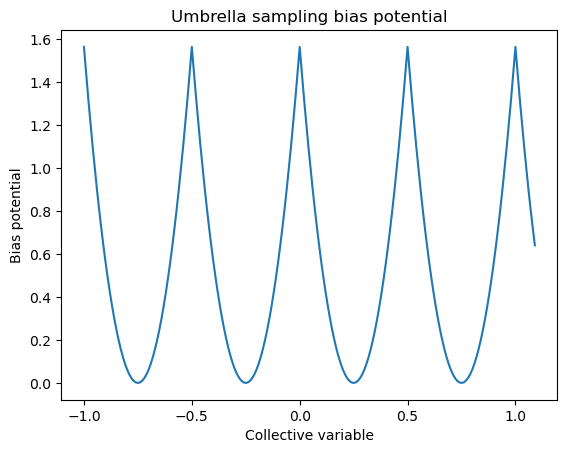

In [31]:
import matplotlib.pyplot as plt

# Define the parameters for the umbrella potential
x0 = 0.0  # Center of the bias potential
k = 50.0  # Spring constant of the bias potential
delta = 0.5 # Spacing between the umbrella windows

# Generate the bias potential values for a range of collective variable values
x_range = np.arange(-1.0, 1.1, 0.01)
bias_potential = [umbrella_potential(x, x0, k, delta) for x in x_range]

# Plot the umbrella sampling bias potential
fig, ax = plt.subplots()
ax.plot(x_range, bias_potential)
ax.set_xlabel('Collective variable')
ax.set_ylabel('Bias potential')
ax.set_title('Umbrella sampling bias potential')
plt.show()


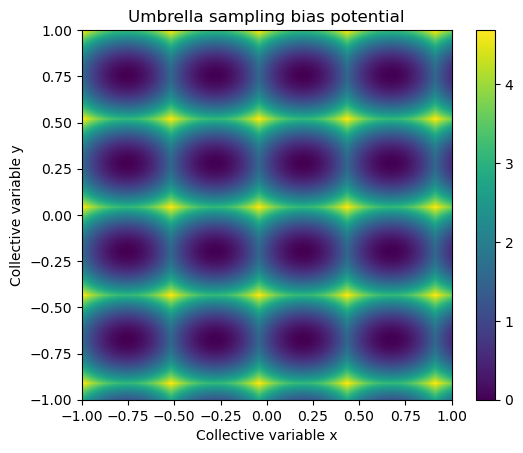

In [29]:
def umbrella_potential(x, y, x0, y0, kx, ky, deltax, deltay):
    dx = np.mod(x - x0, deltax) - deltax / 2.0
    dy = np.mod(y - y0, deltay) - deltay / 2.0
    return 0.5 * kx * dx**2 + 0.5 * ky * dy**2

# Define the parameters for the umbrella potential
x0 = 0.0  # Center of the bias potential in x dimension
y0 = 0.0  # Center of the bias potential in y dimension
kx = 50.0  # Spring constant of the bias potential in x dimension
ky = 100.0  # Spring constant of the bias potential in y dimension
deltax = 0.5  # Spacing between the umbrella windows in x dimension
deltay = 0.5  # Spacing between the umbrella windows in y dimension

# Generate the bias potential values for a grid of collective variable values
x_range = np.arange(-1.0, 1.1, 0.01)
y_range = np.arange(-1.0, 1.1, 0.01)
X, Y = np.meshgrid(x_range, y_range)
bias_potential = umbrella_potential(X, Y, x0, y0, kx, ky, deltax, deltay)

# Plot the 2D umbrella sampling bias potential
fig, ax = plt.subplots()
im = ax.imshow(bias_potential, extent=[-1.0, 1.0, -1.0, 1.0])
ax.set_xlabel('Collective variable x')
ax.set_ylabel('Collective variable y')
ax.set_title('Umbrella sampling bias potential')
plt.colorbar(im)
plt.show()


In [1]:
import numpy as np
from ase.geometry import find_mic
from ase.angle_z_axis import get_z_axis_angle_derv

class ColVar:
    """Base class for collective variables.

    A colvar object must be able to return the value of the collective
    variable through get_colvar() and its gradient via get_colvar_grad.
    To avoid repeated calculations the base class provides a mechanism
    to check if these properties have been evaluated before."""

    def __init__(self):
        self.atoms = None #copy of atoms object from last calculation
        self.cv_value = None
        self.cv_grad = None
        self.counter = 0##

    def get_colvar(self, atoms):
        self.update_colvar(atoms)
        return self.cv_value

    def get_colvar_grad(self, atoms):
        self.update_colvar(atoms)
        return self.cv_grad

    def update_colvar(self, atoms): #, tol=1e-15):
        """check if properties have already been calculated."""

        if self.atoms is None or self.atoms != atoms: #check positions only? (cf. calculator.py)
            self.counter+=1##
            # print('CV computation', self.counter) ##)
            self.compute_cv(atoms)

    def compute_cv(self, atoms):
        """This needs to be implemented in the individual colvar classes.
        Both self.cv_value and self.cv_grad, as well as self.atoms need to be updated."""

        self.atoms = atoms.copy()
       #raise RuntimeError('ColVar class not properly implemented.')


class Dist(ColVar):

    def __init__(self, pair):
        """Distance between two atoms
        pair: list of two atom indices [i0, i1]
        """
        ColVar.__init__(self)
        assert len(pair)==2, "pair has been a list with two atom indices."
        self.pair = pair

    def compute_cv(self, atoms):
        self.atoms = atoms.copy()
        positions = self.atoms.positions
        p1 = positions[self.trip[0]]
        p2 = positions[self.trip[1]]
        p3 = positions[self.trip[2]]

        self.cv_grad = np.zeros_like(positions)

        r_12 = atoms.get_distance(self.pair[0], self.pair[1], mic=True, vector=True)
        dist = atoms.get_distance(self.pair[0], self.pair[1], mic=True)

        self.cv_value = dist
        grad1 = r_12 / dist
        self.cv_grad[self.pair[0]] += grad1
        self.cv_grad[self.pair[1]] -= grad1


class DistDiff(ColVar):

    def __init__(self, triplett):
        """Distance between two atoms
        triplett: list of three atom indices [i0, i1, i2]
        """
        ColVar.__init__(self)
        assert len(triplett)==3, "triplett has been a list with three atom indices."
        self.triplett = triplett

    def compute_cv(self, atoms):
        self.atoms = atoms.copy()
        positions = self.atoms.positions
        self.cv_grad = np.zeros_like(positions)

        p1, p2, p3 = positions[self.triplett]
        # Define distance_1
        displace_1, _ = find_mic(p1 - p2, self.atoms.cell, self.atoms.pbc)
        distance_1 = np.linalg.norm(displace_1)
        # Define distance_2
        displace_2, _ = find_mic(p3 - p1, atoms.cell, atoms.pbc)
        distance_2 = np.linalg.norm(displace_2)
        # Define difference between both distances as new CV
        distance = distance_2 - distance_1

        grad_2 = displace_1 / np.linalg.norm(displace_1)
        grad_3 = displace_2 / np.linalg.norm(displace_2)
        grad_1 = grad_3 + grad_2

        self.cv_value = distance
        self.cv_grad[self.triplett[0]] -= grad_1
        self.cv_grad[self.triplett[1]] += grad_2
        self.cv_grad[self.triplett[2]] += grad_3


class LinearComb(ColVar):

    def __init__(self, trip, lc=[1, 1]):
        """Distance between two atoms
        pair: list of two atom indices [i0, i1]
        lc: linear combination
        """

        ColVar.__init__(self)
        assert len(trip)==3, "trip has been a list with three atom indices."
        self.trip = trip
        self.lc = lc

    def compute_cv(self, atoms):
        self.atoms = atoms.copy()
        positions = self.atoms.positions
        p1 = positions[self.trip[0]]
        p2 = positions[self.trip[1]]
        p3 = positions[self.trip[2]]

        self.cv_grad = np.zeros_like(positions)


        # Get distance vectors and distances
        displace, _ = find_mic(p2 - p1, atoms.cell, atoms.pbc)
        bondlength = np.linalg.norm(displace)

        d_p3_p1, _ = find_mic(p3 - p1, atoms.cell, atoms.pbc)
        norm_p3_p1 = np.linalg.norm(d_p3_p1)

        # Get angle with z axis
        z_axis = np.array([0, 0, 1])
        theta = np.arccos(np.dot(z_axis, d_p3_p1)/(np.linalg.norm(z_axis)*norm_p3_p1))

        # magnitude = self.spring * (bondlength - self.threshold)
        direction = displace / np.linalg.norm(displace)

        angle_derv = get_z_axis_angle_derv(p1, p3, const=self.lc[1])

        self.cv_value = self.lc[0] * bondlength + self.lc[1] * theta
        self.cv_grad[self.trip[0]] = angle_derv[0] - self.lc[0] * direction
        self.cv_grad[self.trip[1]] = self.lc[0] * direction
        self.cv_grad[self.trip[2]] = angle_derv[1]

ModuleNotFoundError: No module named 'ase.angle_z_axis'